# **3. Baseline Lexical e Comparação por `score_mean`**

Este notebook compara o método final do notebook 2 com uma baseline mais forte, porém ainda simples e interpretável.

A comparação **não usa acurácia**, porque não há rótulo oficial externo. A taxonomia final do notebook 2 é uma construção metodológica do próprio projeto, não um ground truth supervisionado.

A pergunta aqui é:

> Se usarmos uma abordagem lexical simples, sem embeddings, fine-tuning ou BERTopic, conseguimos classificar todos os textos nos mesmos 18 grupos com representatividade parecida?

A baseline usada aqui combina duas etapas:

1. regras lexicais para padrões muito característicos, como `simulação`, `protesto`, `retardar reinício`, `toque de mão` e `clara oportunidade de gol`;
2. fallback por `TF-IDF` contra protótipos textuais dos 18 grupos, garantindo que todo texto receba exatamente um grupo.

A comparação final usa apenas o `score_mean`: similaridade média do texto ao centroide ponderado do grupo no espaço de embeddings fine-tunado.


## **1. Configuração e Dados**

Entrada principal:

- `card_reason_unique_topics_labels.csv`: textos únicos, frequências e grupos finais do notebook 2;
- modelo fine-tunado em `models/football_card_reason_e5_large_two_pass`.

A baseline usa somente o texto normalizado para atribuir grupos. Os grupos finais entram como referência de comparação e para manter o mesmo conjunto de 18 categorias.


In [1]:
from pathlib import Path
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer

pd.set_option("display.max_colwidth", 220)
plt.style.use("default")
plt.rcParams.update({
    "axes.grid": False,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10,
    "legend.title_fontsize": 11,
    "font.size": 11,
})

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"
CARD_OUTPUT_DIR = DATA_PATH / "processed" / "semantic_reasons" / "card_reasons"
BASELINE_OUTPUT_DIR = DATA_PATH / "processed" / "semantic_reasons" / "baseline_tests"
VIZ_PATH = PROJECT_ROOT / "viz"

BASELINE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VIZ_PATH.mkdir(parents=True, exist_ok=True)

FINAL_LABELS_PATH = CARD_OUTPUT_DIR / "card_reason_unique_topics_labels.csv"
FINETUNED_MODEL_DIR = MODELS_DIR / "football_card_reason_e5_large_two_pass"

ENCODE_PREFIX_PASSAGE = "passage: "

PLOT_BLUE = "#3D79F3"
PLOT_GREEN = "#34A74B"
PLOT_GRAY = "#909090"


def normalize_text(text: str) -> str:
    text = unicodedata.normalize("NFKD", str(text))
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = text.casefold()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def style_axis(ax, title=None, xlabel=None, ylabel=None, x_rotation=0):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(0.8)
    ax.tick_params(axis="both", colors="black", width=0.8, length=4, pad=7)
    ax.tick_params(axis="x", labelrotation=x_rotation)
    if title is not None:
        ax.set_title(title, fontweight="bold", pad=14)
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontweight="bold", labelpad=12)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontweight="bold", labelpad=12)


def save_plot(fig, filename: str) -> None:
    fig.savefig(VIZ_PATH / filename, dpi=300, bbox_inches="tight")


/Users/gcarninatto/Documents/GitHub/cbf-match-reports-nlp/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
card_terms = pd.read_csv(FINAL_LABELS_PATH, keep_default_na=False)
required_columns = {"card_reason_text_key", "text_for_embedding", "n_events", "card_reason_group"}
missing_columns = required_columns - set(card_terms.columns)
if missing_columns:
    raise ValueError(f"Colunas ausentes em {FINAL_LABELS_PATH}: {sorted(missing_columns)}")

card_terms = card_terms.copy()
card_terms["baseline_text"] = card_terms["card_reason_text_key"].map(normalize_text)
card_terms = card_terms[card_terms["baseline_text"].ne("")].reset_index(drop=True)

final_groups = sorted(card_terms["card_reason_group"].unique())
print(f"Textos únicos: {len(card_terms):,}")
print(f"Eventos/cartões: {int(card_terms['n_events'].sum()):,}")
print(f"Grupos finais: {len(final_groups)}")
card_terms[["text_for_embedding", "n_events", "card_reason_group"]].head(10)


Textos únicos: 6,945
Eventos/cartões: 25,834
Grupos finais: 18


,text_for_embedding,n_events,card_reason_group
0,Por calçar seu adversário de maneira temerária na disputa de bola.,503,Ação temerária
1,"Por cometer uma falta tática, impedindo um ataque promissor.",411,Falta tática em ataque promissor
2,Por retardar o reinicio de jogo,333,Retardar reinício do jogo
3,Cometer uma falta tática para impedir um ataque promissor.,286,Falta tática em ataque promissor
4,Por cometer uma falta tática para impedir um ataque promissor.,251,Falta tática em ataque promissor
5,"Por calçar seu adversário de maneira temerária, na disputa da bola",237,Ação temerária
6,Por calçar seu adversário de forma temerária na disputa de bola.,230,Ação temerária
7,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.,224,Ação temerária
8,Por impedir um ataque promissor.,203,Falta tática em ataque promissor
9,Por reclamar contra as decisões da arbitragem.,202,Protesto contra a arbitragem


## **2. Baseline: Regras Lexicais + TF-IDF por Protótipos**

Esta baseline tenta escolher diretamente entre os 18 grupos finais.

A lógica é:

1. aplicar regras lexicais em ordem de especificidade;
2. para os textos não cobertos pelas regras, calcular similaridade `TF-IDF` entre o texto e uma descrição curta de cada grupo;
3. atribuir o grupo com maior similaridade lexical.

Com esse fallback, nenhum texto fica sem classificação.


In [3]:
PORTUGUESE_STOPWORDS = {
    "a", "ao", "aos", "as", "com", "como", "da", "das", "de", "do", "dos", "e", "em", "na", "nas",
    "no", "nos", "o", "os", "ou", "para", "por", "que", "se", "sem", "um", "uma", "uns", "umas",
    "apos", "ate", "contra", "durante", "forma", "maneira", "motivo", "pela", "pelo", "pelas", "pelos",
    "num", "numa", "ter", "tendo", "dado", "haver", "havendo", "advertido", "advertida", "advertir",
    "adversario", "adversaria", "atleta", "jogador", "jogadora", "sr", "sra", "senhor", "senhora", "numero",
    "n", "equipe", "bola", "campo", "disputa", "jogada", "jogo", "partida", "seu", "sua", "seus", "suas",
    "foi", "foram", "cartao", "amarelo", "vermelho", "expulso", "expulsei", "referido", "informo",
}

BASELINE_GROUP_PROTOTYPES = {
    "Agarrar ou segurar adversário": "segurar agarrar puxar adversario camisa braco cintura impedir movimento reter segurar de forma acintosa agarrar de maneira acintosa puxao segurar adversario",
    "Ação temerária": "acao temeraria entrada temeraria calcar adversario carrinho imprudente atingir perna tornozelo pe disputa bola solada falta temeraria dar entrada disputar bola",
    "Comemoração irregular": "comemoracao irregular comemorar gol tirar camisa retirar camisa subir alambrado entrar campo comemorar gol camisa por cima cabeca",
    "Conduta antidesportiva": "conduta antidesportiva atitude antidesportiva desrespeito jogo mostrar desrespeito ao jogo comportamento antidesportivo",
    "Conduta violenta": "conduta violenta agressao agredir soco tapa chute cabecada cotovelada cuspir cuspida desferir golpe fora disputa bola bola fora jogo violentamente",
    "Confronto físico com adversário": "empurrar adversario trocar empurroes desentendimento confronto fisico peitar adversario tumulto discutir com adversario bola fora jogo empurrao",
    "Entrar ou sair do campo sem autorização": "entrar campo sem autorizacao permissao arbitragem retornar campo abandonar campo invadir area revisao ara marcas nao autorizadas sair campo sem permissao",
    "Falta tática em ataque promissor": "falta tatica impedir ataque promissor ataque promissor contra ataque promissor calcar segurar puxar impedir jogada promissora",
    "Gesto ou linguagem ofensiva": "gesto ofensivo linguagem ofensiva palavras ofensivas xingar xingamento insultar ofender baixo calao palavroes proferir palavras dedo em riste bater palmas ironicas",
    "Impedir clara oportunidade de gol": "impedir clara oportunidade gol oportunidade clara gol chance clara gol situacao clara manifesta gol dogso impedir gol ultimo defensor",
    "Infringir persistentemente as regras": "infringir persistentemente regras jogo persistir infracoes varias faltas numero diferentes infracoes repetidas infracoes persistentes",
    "Insubordinação da comissão técnica": "comissao tecnica area tecnica banco reservas tecnico auxiliar preparador treinador massagista suplentes sair area tecnica reclamar protestar banco",
    "Jogo brusco grave": "jogo brusco grave forca excessiva uso forca excessiva travas chuteira solada tornozelo canela joelho integridade fisica disputar bola entrada grave",
    "Não respeitar distância regulamentar": "nao respeitar distancia regulamentar barreira tiro livre tiro canto cobranca distancia bola parada aproximar barreira",
    "Protesto contra a arbitragem": "protesto arbitragem reclamar decisoes arbitragem desaprovar palavras gestos reclamacao arbitro assistente decisao marcacao contestar",
    "Retardar reinício do jogo": "retardar reinicio jogo retardar partida atrasar reinicio demorar repor bola chutar bola longe prender bola impedir cobranca reposicao",
    "Simulação": "simulacao simular falta simular penalti tentar enganar arbitro ludibriar arbitragem fingir sofrer falta cavar penalidade",
    "Toque de mão na bola": "toque mao bola tocar bola mao colocar mao bola bloquear braco mao deliberadamente interceptar bola com mao mao na bola maos na bola",
}

missing_prototypes = sorted(set(final_groups) - set(BASELINE_GROUP_PROTOTYPES))
extra_prototypes = sorted(set(BASELINE_GROUP_PROTOTYPES) - set(final_groups))
if missing_prototypes or extra_prototypes:
    raise ValueError(
        "Protótipos incompatíveis com os grupos finais. "
        f"Ausentes: {missing_prototypes}; extras: {extra_prototypes}"
    )

BASELINE_RULES = [
    ("Impedir clara oportunidade de gol", [
        r"(dogso|clara oportunidade de gol|oportunidade clara de gol|chance clara de gol|situacao clara.*gol|clara.*manifesta.*gol|impedir.*gol)",
    ]),
    ("Simulação", [r"simul", r"engan.*arbitr", r"ludibri"]),
    ("Comemoração irregular", [r"comemor", r"tirar.*camisa", r"retirar.*camisa", r"camisa.*cabeca", r"alambrado"]),
    ("Não respeitar distância regulamentar", [r"distancia regulament", r"distancia da barreira", r"nao respeitar.*distancia", r"barreira.*tiro livre"]),
    ("Infringir persistentemente as regras", [r"infringir persistent", r"persist.*regras", r"numero.*diferentes.*infrac", r"diferentes infrac"]),
    ("Gesto ou linguagem ofensiva", [
        r"linguagem ofens", r"gesto ofens", r"palavras ofens", r"baixo calao", r"xing", r"insult", r"ofend",
        r"profer.*palavr", r"dedo em riste", r"palmas.*ironic",
    ]),
    ("Insubordinação da comissão técnica", [
        r"area tecnica", r"banco de reserva", r"banco de suplente", r"comissao tecnica", r"auxiliar tecnico",
        r"tecnico da equipe", r"treinador", r"preparador fisico", r"massagista",
    ]),
    ("Protesto contra a arbitragem", [r"reclam", r"protest", r"desaprovar", r"contest", r"decis.*arbitr", r"marcac.*arbitr"]),
    ("Retardar reinício do jogo", [
        r"retardar", r"atrasar.*reinicio", r"demorar.*reinicio", r"chut.*bola.*longe", r"bola.*longe",
        r"prender.*bola", r"nao devolver.*bola",
    ]),
    ("Entrar ou sair do campo sem autorização", [
        r"entrar.*campo.*sem.*(autoriz|permiss)", r"retornar.*campo.*sem", r"abandonar.*campo.*sem",
        r"invadir.*(ara|area de revisao)", r"marcas nao autorizadas",
    ]),
    ("Conduta violenta", [
        r"conduta violenta", r"agred", r"agress", r"desferir", r"soco", r"tapa", r"cuspi", r"cusp",
        r"fora da disputa.*(golp|chut|empurr|cotovel)", r"bola fora.*(golp|chut|empurr|cotovel)",
    ]),
    ("Jogo brusco grave", [r"jogo brusco grave", r"forca excessiva", r"travas? da chuteira", r"solad", r"integridade fisica", r"entrada.*grave"]),
    ("Ação temerária", [r"temerari", r"calcar", r"entrada.*disputa", r"carrinho", r"atingir.*(perna|pe|tornozelo)"]),
    ("Toque de mão na bola", [
        r"mao na bola|maos na bola|braco na bola",
        r"(tocar|toca|colocar|coloca|bloquear|bloqueia|interceptar|intercepta|cortar|corta|jogar|joga|dominar|domina|controlar|controla).{0,45}bola.{0,45}(mao|maos|braco|bracos)",
        r"(tocar|toca|colocar|coloca|bloquear|bloqueia|interceptar|intercepta|cortar|corta|jogar|joga|dominar|domina|controlar|controla).{0,45}(mao|maos|braco|bracos).{0,45}bola",
        r"(mao|maos|braco|bracos).{0,45}bola.{0,60}(deliberad|intencional|impedindo ataque promissor|tentar marcar|direcao ao gol|em direcao ao gol|arremate ao gol|chute ao gol)",
    ]),
    ("Falta tática em ataque promissor", [r"ataque promissor", r"falta tatica", r"contra ataque", r"jogada promissora"]),
    ("Agarrar ou segurar adversário", [r"segur", r"agarr", r"puxar", r"puxao"]),
    ("Confronto físico com adversário", [r"empurr", r"empurroes", r"desentend", r"confront", r"tumulto", r"peitar", r"trocar.*empurr"]),
    ("Conduta antidesportiva", [r"conduta antidesport", r"atitude antidesport", r"desrespeito ao jogo", r"mostrar desrespeito"]),
]

compiled_rules = [(group, [re.compile(pattern) for pattern in patterns]) for group, patterns in BASELINE_RULES]


def assign_by_rule(text: str) -> str | None:
    for group, patterns in compiled_rules:
        if any(pattern.search(text) for pattern in patterns):
            return group
    return None


card_terms["baseline_rule_group"] = card_terms["baseline_text"].map(assign_by_rule)

prototype_df = pd.DataFrame({
    "group": list(BASELINE_GROUP_PROTOTYPES),
    "prototype_text": [normalize_text(text) for text in BASELINE_GROUP_PROTOTYPES.values()],
})

prototype_vectorizer = TfidfVectorizer(
    ngram_range=(1, 3),
    min_df=1,
    max_df=1.0,
    stop_words=sorted(PORTUGUESE_STOPWORDS),
    sublinear_tf=True,
    norm="l2",
)
all_baseline_docs = pd.concat([card_terms["baseline_text"], prototype_df["prototype_text"]], ignore_index=True)
tfidf_matrix = prototype_vectorizer.fit_transform(all_baseline_docs)
text_matrix = tfidf_matrix[:len(card_terms)]
prototype_matrix = tfidf_matrix[len(card_terms):]
prototype_similarity = (text_matrix @ prototype_matrix.T).toarray()

best_prototype_idx = prototype_similarity.argmax(axis=1)
card_terms["baseline_prototype_group"] = prototype_df["group"].to_numpy()[best_prototype_idx]
card_terms["baseline_prototype_score"] = prototype_similarity[np.arange(len(card_terms)), best_prototype_idx]
card_terms["baseline_group"] = card_terms["baseline_rule_group"].fillna(card_terms["baseline_prototype_group"])
card_terms["baseline_source"] = np.where(card_terms["baseline_rule_group"].notna(), "rule", "tfidf_prototype")

if card_terms["baseline_group"].isna().any():
    raise ValueError("A baseline deixou textos sem classificação.")

missing_baseline_groups = sorted(set(final_groups) - set(card_terms["baseline_group"].unique()))
if missing_baseline_groups:
    raise ValueError(f"A baseline não atribuiu textos aos grupos: {missing_baseline_groups}")

print(f"Textos classificados pela baseline: {card_terms['baseline_group'].notna().sum():,}/{len(card_terms):,}")
print(f"Eventos classificados pela baseline: {int(card_terms['n_events'].sum()):,}")
print("Fonte da classificação por eventos:")
print(card_terms.groupby("baseline_source")["n_events"].sum().sort_values(ascending=False).to_string())


Textos classificados pela baseline: 6,945/6,945
Eventos classificados pela baseline: 25,834
Fonte da classificação por eventos:
baseline_source
rule               24374
tfidf_prototype     1460


In [4]:
baseline_source_events = (
    card_terms.pivot_table(
        index="baseline_group",
        columns="baseline_source",
        values="n_events",
        aggfunc="sum",
        fill_value=0,
    )
    .rename(columns={"rule": "rule_events", "tfidf_prototype": "tfidf_prototype_events"})
    .reset_index()
)
for column in ["rule_events", "tfidf_prototype_events"]:
    if column not in baseline_source_events:
        baseline_source_events[column] = 0

baseline_assignment_summary = (
    card_terms.groupby("baseline_group")
    .agg(
        n_events=("n_events", "sum"),
        n_unique_texts=("text_for_embedding", "size"),
        prototype_score_mean=("baseline_prototype_score", "mean"),
    )
    .reset_index()
    .merge(baseline_source_events, on="baseline_group", how="left")
)
baseline_assignment_summary["rule_event_share"] = (
    baseline_assignment_summary["rule_events"] / baseline_assignment_summary["n_events"]
)
baseline_assignment_summary = baseline_assignment_summary.sort_values("n_events", ascending=False).reset_index(drop=True)
baseline_assignment_summary


,baseline_group,n_events,n_unique_texts,prototype_score_mean,rule_events,tfidf_prototype_events,rule_event_share
0,Ação temerária,11298,1936,0.060287,11241,57,0.994955
1,Protesto contra a arbitragem,3904,939,0.072800,3874,30,0.992316
2,Falta tática em ataque promissor,3720,764,0.133922,3539,181,0.951344
3,Retardar reinício do jogo,1791,599,0.075428,1728,63,0.964824
4,Conduta antidesportiva,1396,565,0.081565,1351,45,0.967765
5,Confronto físico com adversário,878,416,0.066047,769,109,0.875854
6,Insubordinação da comissão técnica,469,311,0.081018,467,2,0.995736
7,Agarrar ou segurar adversário,465,234,0.066772,0,465,0.000000
8,Comemoração irregular,451,270,0.124649,437,14,0.968958
9,Infringir persistentemente as regras,325,119,0.120852,250,75,0.769231


In [5]:
baseline_examples = (
    card_terms.sort_values(["baseline_group", "n_events"], ascending=[True, False])
    .groupby("baseline_group")
    .head(5)
    [["baseline_group", "baseline_source", "n_events", "baseline_prototype_score", "text_for_embedding"]]
    .reset_index(drop=True)
)
baseline_examples.head(50)


,baseline_group,baseline_source,n_events,baseline_prototype_score,text_for_embedding
0,Agarrar ou segurar adversário,tfidf_prototype,32,0.212662,Por segurar seu adversário de forma acintosa.
1,Agarrar ou segurar adversário,tfidf_prototype,22,0.032182,Segurar um adversário por motivo tático para afasta-lo da bola.
2,Agarrar ou segurar adversário,tfidf_prototype,12,0.032182,por segurar seu adversário por motivo tático para afastá-lo da bola.
3,Agarrar ou segurar adversário,tfidf_prototype,10,0.212662,Por segurar o seu adversário de forma acintosa.
4,Agarrar ou segurar adversário,tfidf_prototype,9,0.032182,Por segurar um adversário por motivo tático para afastá- lo da bola.
5,Ação temerária,rule,503,0.078561,Por calçar seu adversário de maneira temerária na disputa de bola.
6,Ação temerária,rule,237,0.078561,"Por calçar seu adversário de maneira temerária, na disputa da bola"
7,Ação temerária,rule,230,0.078561,Por calçar seu adversário de forma temerária na disputa de bola.
8,Ação temerária,rule,224,0.158118,Dar uma entrada contra um adversário de maneira temerária na disputa da bola.
9,Ação temerária,rule,189,0.158118,Por dar uma entrada contra seu adversário de maneira temerária na disputa da bola.


## **3. Diagnóstico de `score_mean` no Mesmo Espaço Semântico**

O diagnóstico usa os embeddings fine-tunados para calcular o centroide ponderado de cada grupo e medir a similaridade média dos textos ao centroide do próprio grupo.

A comparação é feita em dois agrupamentos:

1. `card_reason_group`: grupos finais do notebook 2;
2. `baseline_group`: grupos atribuídos pela baseline lexical.

Como a baseline classifica todos os textos em um dos 18 grupos, a comparação por `score_mean` fica completa grupo a grupo.


In [6]:
embedding_model = SentenceTransformer(str(FINETUNED_MODEL_DIR))
card_embeddings = embedding_model.encode(
    [ENCODE_PREFIX_PASSAGE + text for text in card_terms["text_for_embedding"]],
    normalize_embeddings=True,
    batch_size=64,
    show_progress_bar=True,
)
card_embeddings = np.asarray(card_embeddings)
print(f"Embeddings: {card_embeddings.shape}")


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 8790.26it/s]

Batches:   0%|          | 0/109 [00:00<?, ?it/s]

Batches:   1%|          | 1/109 [00:03<06:06,  3.39s/it]

Batches:   2%|▏         | 2/109 [00:04<04:05,  2.29s/it]

...

Batches:  97%|█████████▋| 106/109 [00:35<00:00,  5.87it/s]

Batches:  98%|█████████▊| 107/109 [00:36<00:00,  5.77it/s]

Batches:  99%|█████████▉| 108/109 [00:36<00:00,  5.80it/s]

Batches: 100%|██████████| 109/109 [00:36<00:00,  3.00it/s]

Embeddings: (6945, 1024)


In [7]:
def score_mean_by_assignment(
    assignment_col: str,
    group_col_name: str,
    embeddings: np.ndarray,
    text_counts: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    group_order = sorted(text_counts[assignment_col].dropna().unique())
    group_to_idx = {group: i for i, group in enumerate(group_order)}
    centroids = []

    for group in group_order:
        mask = text_counts[assignment_col].eq(group).to_numpy()
        weights = text_counts.loc[mask, "n_events"].to_numpy(dtype=float)
        centroid = np.average(embeddings[mask], axis=0, weights=weights)
        centroid_norm = np.linalg.norm(centroid)
        if centroid_norm == 0:
            raise ValueError(f"Centroide nulo para o grupo {group!r}.")
        centroids.append(centroid / centroid_norm)

    centroid_matrix = np.vstack(centroids)
    similarity_to_groups = embeddings @ centroid_matrix.T
    own_idx = text_counts[assignment_col].map(group_to_idx).to_numpy()
    row_idx = np.arange(len(text_counts))

    details = text_counts.copy()
    details["score"] = similarity_to_groups[row_idx, own_idx]

    quality = (
        details.groupby(assignment_col)
        .agg(
            n_events=("n_events", "sum"),
            n_unique_texts=("text_for_embedding", "size"),
            score_mean=("score", "mean"),
        )
        .reset_index()
        .rename(columns={assignment_col: group_col_name})
        .sort_values("score_mean", ascending=True)
    )
    return quality, details


final_quality_recomputed, final_details = score_mean_by_assignment(
    "card_reason_group", "group", card_embeddings, card_terms
)
baseline_quality, baseline_details = score_mean_by_assignment(
    "baseline_group", "group", card_embeddings, card_terms
)

baseline_quality


,group,n_events,n_unique_texts,score_mean
1,Ação temerária,11298,1936,0.578530
7,Falta tática em ataque promissor,3720,764,0.683488
15,Retardar reinício do jogo,1791,599,0.686601
3,Conduta antidesportiva,1396,565,0.711067
5,Confronto físico com adversário,878,416,0.713077
0,Agarrar ou segurar adversário,465,234,0.717631
17,Toque de mão na bola,94,59,0.750362
4,Conduta violenta,148,103,0.783952
2,Comemoração irregular,451,270,0.795367
11,Insubordinação da comissão técnica,469,311,0.821749


## **4. Comparação Grupo a Grupo**

A tabela abaixo compara apenas `score_mean`, mantendo a mesma métrica usada no notebook 2.

A coluna `baseline_n_events` pode diferir de `final_n_events`, porque a baseline pode redistribuir textos entre grupos. Isso faz parte da comparação: o objetivo é observar se a forma simples de classificar gera grupos internamente representativos.


In [8]:
baseline_score_mean = baseline_quality[["group", "n_events", "n_unique_texts", "score_mean"]].rename(columns={
    "group": "card_reason_group",
    "n_events": "baseline_n_events",
    "n_unique_texts": "baseline_n_unique_texts",
    "score_mean": "baseline_score_mean",
})

baseline_source_by_group = baseline_assignment_summary[[
    "baseline_group", "rule_events", "tfidf_prototype_events", "rule_event_share"
]].rename(columns={"baseline_group": "card_reason_group"})

score_mean_by_group = (
    final_quality_recomputed[["group", "n_events", "n_unique_texts", "score_mean"]]
    .rename(columns={
        "group": "card_reason_group",
        "n_events": "final_n_events",
        "n_unique_texts": "final_n_unique_texts",
        "score_mean": "final_score_mean",
    })
    .merge(baseline_score_mean, on="card_reason_group", how="left")
    .merge(baseline_source_by_group, on="card_reason_group", how="left")
)

score_mean_by_group["score_mean_delta_baseline_minus_final"] = (
    score_mean_by_group["baseline_score_mean"] - score_mean_by_group["final_score_mean"]
)
score_mean_by_group = score_mean_by_group.sort_values("final_score_mean", ascending=True).reset_index(drop=True)
score_mean_by_group


,card_reason_group,final_n_events,final_n_unique_texts,final_score_mean,baseline_n_events,baseline_n_unique_texts,baseline_score_mean,rule_events,tfidf_prototype_events,rule_event_share,score_mean_delta_baseline_minus_final
0,Ação temerária,11465,1993,0.580176,11298,1936,0.578530,11241,57,0.994955,-0.001646
1,Retardar reinício do jogo,1852,637,0.670170,1791,599,0.686601,1728,63,0.964824,0.016431
2,Agarrar ou segurar adversário,1174,559,0.686851,465,234,0.717631,0,465,0.000000,0.030780
3,Falta tática em ataque promissor,3575,710,0.696393,3720,764,0.683488,3539,181,0.951344,-0.012906
4,Confronto físico com adversário,927,440,0.714481,878,416,0.713077,769,109,0.875854,-0.001403
5,Conduta antidesportiva,595,214,0.723986,1396,565,0.711067,1351,45,0.967765,-0.012919
6,Comemoração irregular,447,271,0.804899,451,270,0.795367,437,14,0.968958,-0.009532
7,Insubordinação da comissão técnica,483,318,0.816279,469,311,0.821749,467,2,0.995736,0.005471
8,Conduta violenta,176,132,0.826128,148,103,0.783952,110,38,0.743243,-0.042175
9,Impedir clara oportunidade de gol,171,128,0.850884,137,103,0.836630,0,137,0.000000,-0.014254


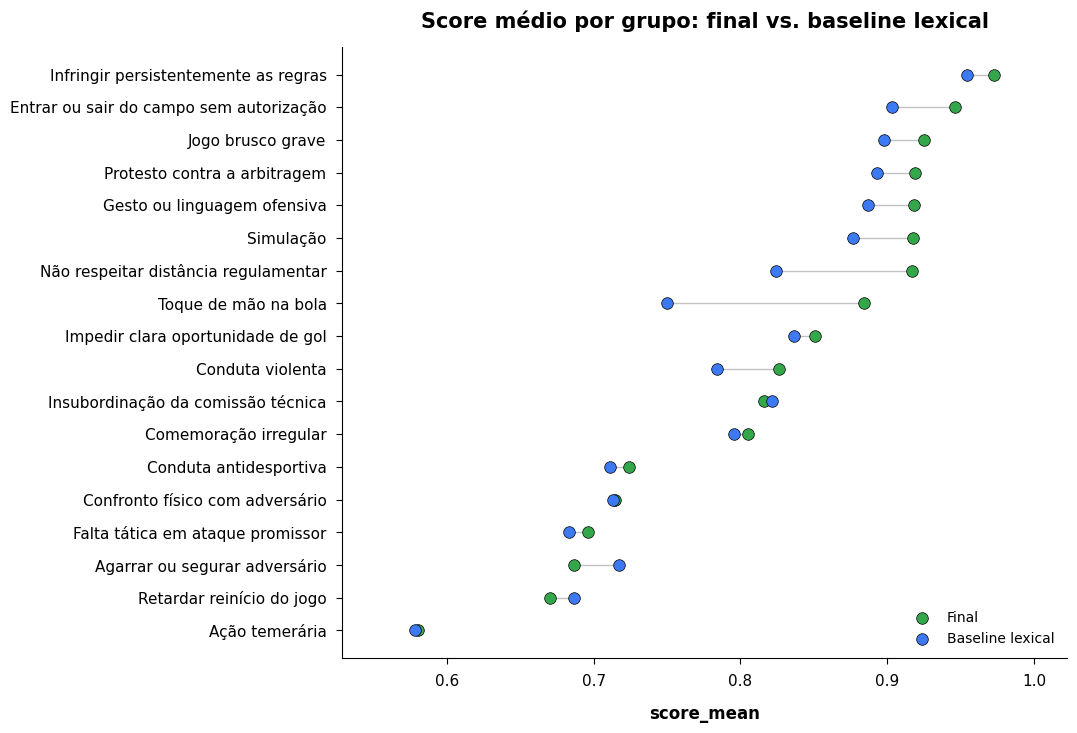

In [9]:
plot_df = score_mean_by_group.sort_values("final_score_mean", ascending=True).reset_index(drop=True)
y_pos = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(11, max(6.5, 0.42 * len(plot_df))))

for idx, row in plot_df.iterrows():
    ax.plot(
        [row["final_score_mean"], row["baseline_score_mean"]],
        [idx, idx],
        color=PLOT_GRAY,
        linewidth=1.0,
        alpha=0.55,
        zorder=1,
    )

ax.scatter(
    plot_df["final_score_mean"],
    y_pos,
    color=PLOT_GREEN,
    edgecolor="black",
    linewidth=0.5,
    s=70,
    label="Final",
    zorder=3,
)
ax.scatter(
    plot_df["baseline_score_mean"],
    y_pos,
    color=PLOT_BLUE,
    edgecolor="black",
    linewidth=0.5,
    s=70,
    label="Baseline lexical",
    zorder=3,
)

score_values = pd.concat([plot_df["final_score_mean"], plot_df["baseline_score_mean"]]).dropna()
ax.set_xlim(max(0.0, score_values.min() - 0.05), min(1.04, score_values.max() + 0.05))
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df["card_reason_group"])
style_axis(ax, "Score médio por grupo: final vs. baseline lexical", "score_mean", None)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(pad=1.4)
save_plot(fig, "baseline_tfidf_prototype_score_mean_by_group.png")
plt.show()


## **5. Salvamento dos Artefatos**

In [10]:
baseline_labels_path = BASELINE_OUTPUT_DIR / "tfidf_prototype_unique_labels.csv"
baseline_assignment_summary_path = BASELINE_OUTPUT_DIR / "tfidf_prototype_assignment_summary.csv"
baseline_examples_path = BASELINE_OUTPUT_DIR / "tfidf_prototype_examples.csv"
final_quality_path = BASELINE_OUTPUT_DIR / "final_score_mean_recomputed.csv"
baseline_quality_path = BASELINE_OUTPUT_DIR / "tfidf_prototype_score_mean.csv"
score_mean_by_group_path = BASELINE_OUTPUT_DIR / "tfidf_prototype_score_mean_by_group.csv"

card_terms.to_csv(baseline_labels_path, index=False)
baseline_assignment_summary.to_csv(baseline_assignment_summary_path, index=False)
baseline_examples.to_csv(baseline_examples_path, index=False)
final_quality_recomputed.to_csv(final_quality_path, index=False)
baseline_quality.to_csv(baseline_quality_path, index=False)
score_mean_by_group.to_csv(score_mean_by_group_path, index=False)

pd.Series({
    "baseline_labels": str(baseline_labels_path.relative_to(PROJECT_ROOT)),
    "baseline_assignment_summary": str(baseline_assignment_summary_path.relative_to(PROJECT_ROOT)),
    "baseline_examples": str(baseline_examples_path.relative_to(PROJECT_ROOT)),
    "final_score_mean_recomputed": str(final_quality_path.relative_to(PROJECT_ROOT)),
    "baseline_score_mean": str(baseline_quality_path.relative_to(PROJECT_ROOT)),
    "score_mean_by_group": str(score_mean_by_group_path.relative_to(PROJECT_ROOT)),
})


baseline_labels                      data/processed/semantic_reasons/baseline_tests/tfidf_prototype_unique_labels.csv
baseline_assignment_summary     data/processed/semantic_reasons/baseline_tests/tfidf_prototype_assignment_summary.csv
baseline_examples                         data/processed/semantic_reasons/baseline_tests/tfidf_prototype_examples.csv
final_score_mean_recomputed            data/processed/semantic_reasons/baseline_tests/final_score_mean_recomputed.csv
baseline_score_mean                     data/processed/semantic_reasons/baseline_tests/tfidf_prototype_score_mean.csv
score_mean_by_group            data/processed/semantic_reasons/baseline_tests/tfidf_prototype_score_mean_by_group.csv
dtype: object

## **6. Conclusões**

A baseline lexical é mais forte que o `TF-IDF + NMF` anterior para este objetivo, porque classifica diretamente nos 18 grupos e não depende de um mapeamento posterior de tópicos dominantes.

Ainda assim, ela permanece uma baseline: usa padrões de palavras e similaridade lexical, sem embeddings, fine-tuning, BERTopic ou auditoria manual de clusters. Isso torna o método simples e defensável como comparação inicial.

A leitura principal deve ser feita pela tabela e pelo gráfico de `score_mean`: quando a baseline se aproxima do método final, os padrões lexicais já eram suficientes; quando ela fica abaixo, há indício de que o método final organiza melhor variações textuais, ambiguidades e descrições longas das súmulas.
